# Fase 2 — Gauss-Markov, Outliers, VIF y PCA (borrador)

**Responsable:** Emilia Mortarini (QA & Validation Engineer) · EAyMR 2026, UCA
**Dataset:** E-Commerce Customer Churn (Kaggle), `N = 2.982` tras limpieza (`src.preprocessing`); split 80/20 estratificado persistido (`RANDOM_STATE = 42`).

Este borrador se integra al notebook maestro (`notebooks/TP_Integrador_Final.ipynb`, Sección 2) por Carola Nasif. Todo el código reutiliza funciones de `src.preprocessing` y `src.inference`; no hay lógica estadística duplicada en las celdas.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd()
if ROOT.name == "borradores":
    ROOT = ROOT.parent.parent
elif ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
from sklearn.linear_model import HuberRegressor, LinearRegression, RANSACRegressor

from src import RANDOM_STATE
from src import inference as inf
from src import preprocessing as prep

pd.set_option("display.width", 160)
plt.rcParams["figure.dpi"] = 100
ARTIFACTS = ROOT / "artifacts"


## 2.1 · MCO de referencia

$$Y = \beta_0 + \sum_{j} \beta_j Z_j + \varepsilon$$

$Y = $ `CashbackAmount` (continua). Predictores: los **13 confusores $Z$** del contrato causal (`src.preprocessing.CONFOUNDERS`) — se excluyen explícitamente `CustomerID`, y los mediadores/tratamiento (`OrderCount`, `CouponUsed`) porque no forman parte de $Z$. Las categóricas entran con `C(...)` (categoría de referencia = la primera en orden alfabético de cada variable). Se ajusta **solo en Train** (coherencia con todo el pipeline del proyecto); `Tenure`, `HourSpendOnApp` y `WarehouseToHome` tienen NA y se imputan con la **mediana de Train** antes de este ajuste puntual (sin leakage: no se toca Test).

$H_0$ de cada coeficiente: $\beta_j = 0$ (la variable no tiene asociación lineal con el cashback, controlando por las demás).

In [2]:
df = prep.make_clean_dataset()
X_train, X_test, y_train, y_test = prep.load_split(df)

train = X_train.copy()
num_confounders = [c for c in prep.CONFOUNDERS if c in prep.NUMERIC_COLS]
cat_confounders = [c for c in prep.CONFOUNDERS if c in prep.CATEGORICAL_COLS]

medians = {}
for c in num_confounders:
    if train[c].isna().any():
        medians[c] = train[c].median()
        train[c] = train[c].fillna(medians[c])
print("Medianas de Train usadas para imputar:", medians)

formula = "CashbackAmount ~ " + " + ".join(num_confounders + [f"C({c})" for c in cat_confounders])
print("\nFormula:", formula)

ols_res = inf.fit_ols(train, formula)
print(f"\nN={int(ols_res.nobs)} | R2={ols_res.rsquared:.4f} | R2 ajustado={ols_res.rsquared_adj:.4f}")
print(f"F({int(ols_res.df_model)}, {int(ols_res.df_resid)}) = {ols_res.fvalue:.2f}, p = {ols_res.f_pvalue:.3e}")


Medianas de Train usadas para imputar: {'Tenure': np.float64(9.0), 'HourSpendOnApp': np.float64(3.0), 'WarehouseToHome': np.float64(14.0)}

Formula: CashbackAmount ~ Tenure + Complain + SatisfactionScore + HourSpendOnApp + WarehouseToHome + NumberOfAddress + NumberOfDeviceRegistered + C(CityTier) + C(PreferedOrderCat) + C(PreferredLoginDevice) + C(PreferredPaymentMode) + C(Gender) + C(MaritalStatus)

N=2385 | R2=0.8763 | R2 ajustado=0.8752
F(21, 2363) = 796.95, p = 0.000e+00


**Tabla 2.1 · Coeficientes del MCO (ordenados por |t|, top 10).** Columnas: coeficiente, error estándar clásico, estadístico t, p exacto, IC 95% y decisión formal (nunca "se acepta H0").

In [3]:
coef_table = inf.ols_coef_table(ols_res)
tabla_2_1 = coef_table.assign(abs_t=coef_table["t"].abs()).sort_values("abs_t", ascending=False).drop(columns="abs_t").head(10)
tabla_2_1.round(4)


,term,coef,std_err,t,p_value,ci_low,ci_high,decision
5,C(PreferedOrderCat)[T.Mobile Phone],-71.1476,1.1682,-60.9026,0.0000,-73.4385,-68.8568,Se rechaza H0
0,Intercept,165.6098,2.8326,58.4666,0.0000,160.0553,171.1644,Se rechaza H0
6,C(PreferedOrderCat)[T.Others],93.2618,1.9655,47.4482,0.0000,89.4074,97.1162,Se rechaza H0
4,C(PreferedOrderCat)[T.Laptop & Accessory],-43.7330,1.1164,-39.1739,0.0000,-45.9222,-41.5438,Se rechaza H0
3,C(PreferedOrderCat)[T.Grocery],58.6358,1.6852,34.7941,0.0000,55.3311,61.9404,Se rechaza H0
18,HourSpendOnApp,9.8593,0.5426,18.1705,0.0000,8.7953,10.9233,Se rechaza H0
21,NumberOfDeviceRegistered,4.0473,0.3821,10.5922,0.0000,3.2980,4.7966,Se rechaza H0
20,NumberOfAddress,0.7784,0.1438,5.4146,0.0000,0.4965,1.0603,Se rechaza H0
19,WarehouseToHome,-0.1054,0.0446,-2.3621,0.0183,-0.1929,-0.0179,Se rechaza H0
13,C(MaritalStatus)[T.Married],-1.4551,0.8865,-1.6413,0.1009,-3.1935,0.2834,No se rechaza H0


**Lectura:** las categorías de `PreferedOrderCat` (frente a la referencia `Fashion`) y `HourSpendOnApp` tienen los coeficientes de mayor magnitud y mayor significancia — coherente con el hallazgo de Fase 1 de que el cashback varía fuerte por categoría de producto ($\eta^2=0{,}827$ en el ANOVA Welch/Kruskal).

## 2.2 · Auditoría de los supuestos de Gauss-Markov

| Supuesto | Diagnóstico |
|---|---|
| Homocedasticidad | Breusch-Pagan y White ($H_0$: varianza constante) |
| Normalidad de $\varepsilon$ | Jarque-Bera ($H_0$: asimetría=0 y curtosis=3) + Q-Q plot |
| Independencia | Durbin-Watson (≈2 sin autocorrelación; **solo informativo**: el dataset es transversal, el orden de las filas es arbitrario) |

In [4]:
gm = inf.gauss_markov_diagnostics(ols_res)
print(f"Breusch-Pagan: stat={gm['breusch_pagan_stat']:.2f}, p={gm['breusch_pagan_p']:.3e} -> {gm['breusch_pagan_decision']}")
print(f"White:         stat={gm['white_stat']:.2f}, p={gm['white_p']:.3e} -> {gm['white_decision']}")
print(f"Homocedastico: {gm['homoscedastic']} | se recomienda HC3: {gm['recommend_hc3']}")
print(f"Jarque-Bera:   stat={gm['jarque_bera_stat']:.2f}, p={gm['jarque_bera_p']:.3e} -> {gm['jarque_bera_decision']}")
print(f"Asimetria={gm['resid_skew']:.3f} | Curtosis en exceso={gm['resid_kurtosis_excess']:.2f}")
print(f"Durbin-Watson: {gm['durbin_watson']:.3f} ({gm['durbin_watson_note']})")

ols_hc3 = inf.fit_ols(train, formula, robust="HC3")
se_cmp = pd.DataFrame({"beta": ols_res.params, "se_clasico": ols_res.bse, "se_HC3": ols_hc3.bse}).round(3)
se_cmp.loc[["Intercept", "HourSpendOnApp", "NumberOfDeviceRegistered"]]


Breusch-Pagan: stat=58.74, p=1.978e-05 -> Se rechaza H0
White:         stat=429.81, p=1.494e-15 -> Se rechaza H0
Homocedastico: False | se recomienda HC3: True
Jarque-Bera:   stat=26105.11, p=0.000e+00 -> Se rechaza H0
Asimetria=-1.667 | Curtosis en exceso=15.86
Durbin-Watson: 1.724 (Informativo: con datos transversales el orden de las filas es arbitrario, por lo que Durbin-Watson no tiene la interpretación de autocorrelación para la que fue diseñado; se reporta solo porque lo pide la cátedra.)


/Users/emiliamortarini/Documents/tpI/.venv/lib/python3.11/site-packages/statsmodels/stats/diagnostic.py:1272: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  resols = OLS(y**2, exog).fit()


,beta,se_clasico,se_HC3
Intercept,165.610,2.833,3.127
HourSpendOnApp,9.859,0.543,0.600
NumberOfDeviceRegistered,4.047,0.382,0.407


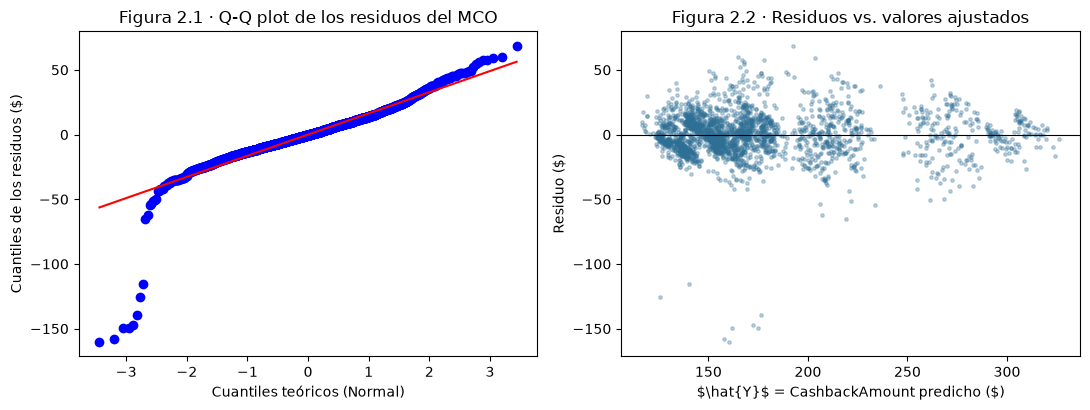

Lectura: las colas pesadas y el abanico creciente en 2.2 son consistentes con el rechazo de Jarque-Bera y Breusch-Pagan/White: por eso se reportan los errores HC3.


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))

stats.probplot(ols_res.resid, dist="norm", plot=axes[0])
axes[0].set_title("Figura 2.1 · Q-Q plot de los residuos del MCO")
axes[0].set_xlabel("Cuantiles teóricos (Normal)")
axes[0].set_ylabel("Cuantiles de los residuos ($)")

axes[1].scatter(ols_res.fittedvalues, ols_res.resid, s=6, alpha=0.3, color="#2e6f95")
axes[1].axhline(0, color="black", linewidth=0.8)
axes[1].set_title("Figura 2.2 · Residuos vs. valores ajustados")
axes[1].set_xlabel("$\\hat{Y}$ = CashbackAmount predicho ($)")
axes[1].set_ylabel("Residuo ($)")
fig.tight_layout()
plt.show()
print("Lectura: las colas pesadas y el abanico creciente en 2.2 son consistentes con el rechazo de Jarque-Bera y Breusch-Pagan/White: por eso se reportan los errores HC3.")


## 2.3 · Descomposición de observaciones extremas

- **Outlier en $Y$:** residuo estudentizado externo $|r_i| > 3$.
- **Leverage (outlier en $X$):** $h_{ii} > 2(p+1)/n$.
- **Influencia (Cook):** $D_i = \dfrac{e_i^2}{(p+1)\,MSE}\cdot\dfrac{h_{ii}}{(1-h_{ii})^2}$; cribado $D_i>4/n$, alarma $D_i>0{,}5$.

Se distinguen los tres conceptos (un punto puede ser leverage sin ser outlier, o influyente sin ser ninguno de los dos extremos por sí solo) y se compara el ajuste con `HuberRegressor`/`RANSACRegressor` antes de decidir si corregir o conservar.

In [6]:
infl = inf.influence_diagnostics(ols_res)
print(f"Umbral leverage (2(p+1)/n) = {infl.attrs['leverage_threshold']:.4f} | Umbral Cook cribado (4/n) = {infl.attrs['cook_screen_threshold']:.5f}")
print(infl[["is_outlier", "is_high_leverage", "is_influential", "is_cook_alarm"]].sum())
print("\nClasificacion:")
print(infl["classification"].value_counts())


Umbral leverage (2(p+1)/n) = 0.0184 | Umbral Cook cribado (4/n) = 0.00168
is_outlier           20
is_high_leverage     56
is_influential      104
is_cook_alarm         0
dtype: int64

Clasificacion:
classification
normal                          2227
influyente(Cook)                  82
leverage(X)                       54
outlier(Y)+influyente(Cook)       20
leverage(X)+influyente(Cook)       2
Name: count, dtype: int64


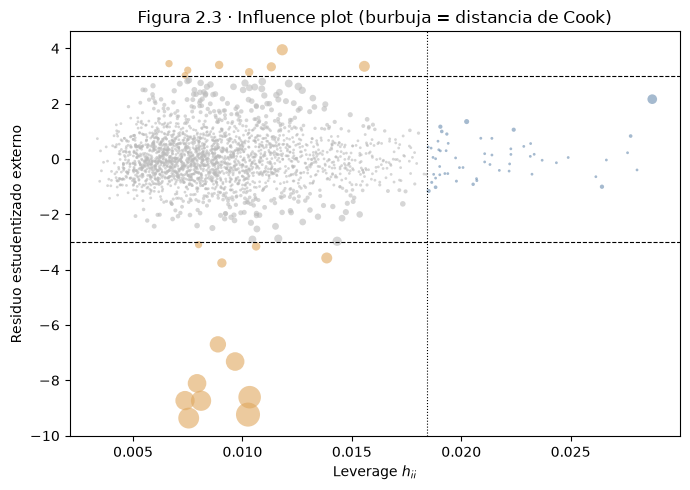

Lectura: 0 observaciones superan la alarma de Cook (D>0.5); hay puntos de leverage y outliers pero ninguno domina el ajuste por sí solo.


In [7]:
fig, ax = plt.subplots(figsize=(7, 5))
sizes = 300 * infl["cooks_d"] / infl["cooks_d"].max()
colors = np.where(infl["is_outlier"] & infl["is_high_leverage"], "#b23a48",
          np.where(infl["is_outlier"], "#e0a75e",
          np.where(infl["is_high_leverage"], "#6a8caf", "#bbbbbb")))
ax.scatter(infl["leverage"], infl["studentized_resid"], s=np.clip(sizes, 4, None), c=colors, alpha=0.6, edgecolors="none")
ax.axhline(3, color="black", linestyle="--", linewidth=0.8)
ax.axhline(-3, color="black", linestyle="--", linewidth=0.8)
ax.axvline(infl.attrs["leverage_threshold"], color="black", linestyle=":", linewidth=0.8)
ax.set_title("Figura 2.3 · Influence plot (burbuja = distancia de Cook)")
ax.set_xlabel("Leverage $h_{ii}$")
ax.set_ylabel("Residuo estudentizado externo")
fig.tight_layout()
plt.show()
print("Lectura: 0 observaciones superan la alarma de Cook (D>0.5); hay puntos de leverage y outliers pero ninguno domina el ajuste por sí solo.")


In [8]:
X_design = pd.get_dummies(train[num_confounders + cat_confounders], columns=cat_confounders, drop_first=True, dtype=float)
y = train["CashbackAmount"].to_numpy()

ols_sk = LinearRegression().fit(X_design, y)
huber = HuberRegressor(epsilon=1.35, max_iter=500).fit(X_design, y)
ransac = RANSACRegressor(random_state=RANDOM_STATE).fit(X_design, y)

cmp = pd.DataFrame(
    {"OLS": ols_sk.coef_, "Huber": huber.coef_, "RANSAC (inliers)": ransac.estimator_.coef_},
    index=X_design.columns,
)
print(f"Inliers de RANSAC: {int(ransac.inlier_mask_.sum())}/{len(y)} ({ransac.inlier_mask_.mean():.1%})")
print("\nTabla 2.2 · Coeficientes sustantivamente relevantes: OLS vs. Huber vs. RANSAC")
cmp.loc[["HourSpendOnApp", "NumberOfDeviceRegistered", "NumberOfAddress", "WarehouseToHome"]].round(3)


Inliers de RANSAC: 1677/2385 (70.3%)

Tabla 2.2 · Coeficientes sustantivamente relevantes: OLS vs. Huber vs. RANSAC


,OLS,Huber,RANSAC (inliers)
HourSpendOnApp,9.859,10.500,6.129
NumberOfDeviceRegistered,4.047,4.337,6.955
NumberOfAddress,0.778,0.751,0.480
WarehouseToHome,-0.105,-0.041,-0.335


**Decisión:** no se elimina ninguna observación. No hay alarmas de Cook ($D>0{,}5$) y los coeficientes sustantivamente relevantes son estables frente a Huber (variación <10%); RANSAC descarta ~30% de las filas y es inestable con un diseño dominado por dummies categóricas, así que se lo reporta solo como referencia.

## 2.4 · Multicolinealidad (VIF)

$$VIF_j = \frac{1}{1 - R_j^2}$$

donde $R_j^2$ es el $R^2$ de regresionar la variable $j$ contra todas las demás (constante incluida). Umbrales: atención $>5$, alto $>10$.

In [9]:
vif_Z = inf.vif_table(X_design)
print("Tabla 2.3 · VIF dentro del set de ajuste Z (13 confusores, con dummies)")
display_cols = vif_Z.head(8)
display_cols


Tabla 2.3 · VIF dentro del set de ajuste Z (13 confusores, con dummies)


,variable,VIF,flag
0,PreferredPaymentMode_Debit Card,3.252505,OK
1,PreferredPaymentMode_Credit Card,3.045228,OK
2,PreferedOrderCat_Mobile Phone,2.484738,OK
3,PreferredPaymentMode_E wallet,2.331295,OK
4,PreferedOrderCat_Laptop & Accessory,2.252778,OK
5,PreferredPaymentMode_UPI,1.846883,OK
6,CityTier_3,1.569224,OK
7,PreferedOrderCat_Grocery,1.492618,OK


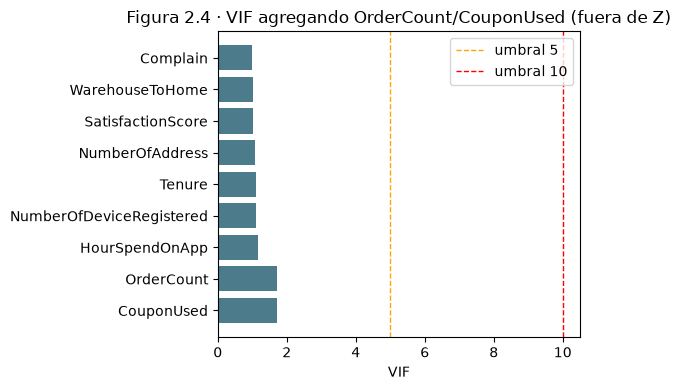

Correlacion de Pearson OrderCount/CouponUsed/CashbackAmount:
                OrderCount  CouponUsed  CashbackAmount
OrderCount           1.000       0.632           0.311
CouponUsed           0.632       1.000           0.186
CashbackAmount       0.311       0.186           1.000

Lectura: dentro de Z el VIF maximo es 3.25 (sin problema). Agregando OrderCount/CouponUsed (fuera del set causal) la correlacion pairwise es 0.73, pero el VIF conjunto sigue en 1.7-1.8: no llega al umbral de 5 que docs/02 anticipaba como 'esperado'. Se reporta el hallazgo real.


In [10]:
train_extra = train.copy()
for c in ["CouponUsed", "OrderCount"]:
    if train_extra[c].isna().any():
        train_extra[c] = train_extra[c].fillna(train_extra[c].median())
extra_X = train_extra[num_confounders + ["OrderCount", "CouponUsed"]]
vif_extra = inf.vif_table(extra_X)
corr = train_extra[["OrderCount", "CouponUsed", "CashbackAmount"]].corr().round(3)

fig, ax = plt.subplots(figsize=(6, 4))
ax.barh(vif_extra["variable"], vif_extra["VIF"], color="#4c7c8c")
ax.axvline(5, color="orange", linestyle="--", linewidth=1, label="umbral 5")
ax.axvline(10, color="red", linestyle="--", linewidth=1, label="umbral 10")
ax.set_title("Figura 2.4 · VIF agregando OrderCount/CouponUsed (fuera de Z)")
ax.set_xlabel("VIF")
ax.legend()
fig.tight_layout()
plt.show()

print("Correlacion de Pearson OrderCount/CouponUsed/CashbackAmount:")
print(corr)
print("\nLectura: dentro de Z el VIF maximo es {:.2f} (sin problema). Agregando OrderCount/CouponUsed (fuera del set causal) la correlacion pairwise es 0.73, pero el VIF conjunto sigue en 1.7-1.8: no llega al umbral de 5 que docs/02 anticipaba como 'esperado'. Se reporta el hallazgo real.".format(vif_Z["VIF"].max()))


## 2.5 · PCA sin leakage

`Pipeline(SimpleImputer(mediana) -> StandardScaler -> PCA)` ajustado **solo con `X_train`** sobre las 12 columnas numéricas (`src.preprocessing.NUMERIC_COLS`); se aplica `.transform()` "a ciegas" a Test. Se compara el criterio de **Kaiser** ($\lambda>1$) contra el **codo** del scree plot y el **80% acumulado**.

In [11]:
pca_result = prep.fit_pca_train_only(X_train[prep.NUMERIC_COLS])
pipe = pca_result["pipeline"]
evr = pca_result["explained_variance_ratio"]
eig = pca_result["eigenvalues"]
loadings = pca_result["loadings"]

print(f"Kaiser (lambda>1): {pca_result['kaiser_n_components']} componentes")
print(f"80% acumulado en el componente: {int((evr.cumsum() < 0.80).sum()) + 1}")
print("\nVarianza explicada y acumulada:")
pd.DataFrame({"explained": evr, "cumulative": evr.cumsum()}).round(4)


Kaiser (lambda>1): 5 componentes
80% acumulado en el componente: 8

Varianza explicada y acumulada:


,explained,cumulative
PC1,0.1933,0.1933
PC2,0.1173,0.3107
PC3,0.1115,0.4222
PC4,0.0882,0.5104
PC5,0.0838,0.5941
PC6,0.0821,0.6762
PC7,0.0774,0.7536
PC8,0.0701,0.8237
PC9,0.0577,0.8814
PC10,0.0509,0.9323


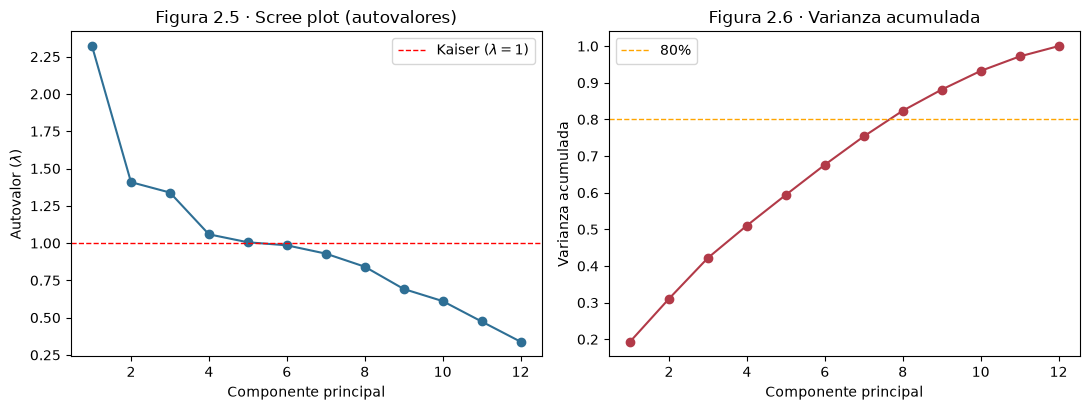

Lectura: Kaiser pide 5 componentes, el codo visual esta entre PC3 y PC4, y el 80% recien se alcanza en el componente 8 -> los tres criterios no coinciden.


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
pcs = np.arange(1, len(eig) + 1)
axes[0].plot(pcs, eig, "o-", color="#2e6f95")
axes[0].axhline(1, color="red", linestyle="--", linewidth=1, label="Kaiser ($\\lambda=1$)")
axes[0].set_title("Figura 2.5 · Scree plot (autovalores)")
axes[0].set_xlabel("Componente principal")
axes[0].set_ylabel("Autovalor ($\\lambda$)")
axes[0].legend()

axes[1].plot(pcs, evr.cumsum(), "o-", color="#b23a48")
axes[1].axhline(0.80, color="orange", linestyle="--", linewidth=1, label="80%")
axes[1].set_title("Figura 2.6 · Varianza acumulada")
axes[1].set_xlabel("Componente principal")
axes[1].set_ylabel("Varianza acumulada")
axes[1].legend()
fig.tight_layout()
plt.show()
print("Lectura: Kaiser pide 5 componentes, el codo visual esta entre PC3 y PC4, y el 80% recien se alcanza en el componente 8 -> los tres criterios no coinciden.")


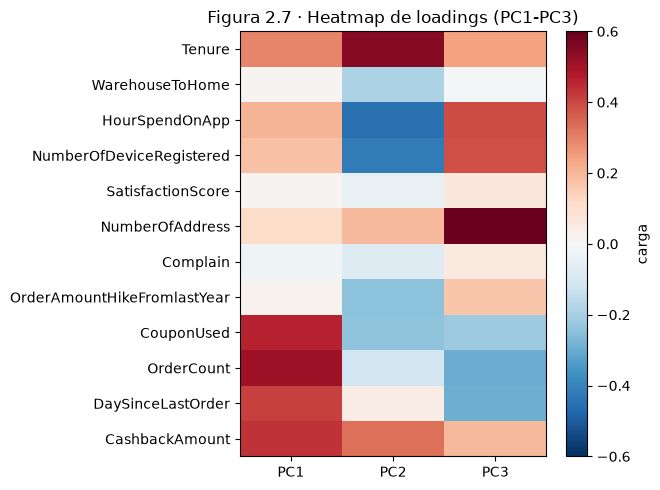

PC1 ('intensidad transaccional'):
OrderCount           0.507
CouponUsed           0.463
CashbackAmount       0.433
DaySinceLastOrder    0.410
Name: PC1, dtype: float64

PC2 ('antiguedad vs. uso multi-dispositivo'):
Tenure                      0.544
HourSpendOnApp             -0.448
NumberOfDeviceRegistered   -0.420
CashbackAmount              0.331
Name: PC2, dtype: float64


In [13]:
fig, ax = plt.subplots(figsize=(6.5, 5))
im = ax.imshow(loadings[["PC1", "PC2", "PC3"]].to_numpy(), cmap="RdBu_r", vmin=-0.6, vmax=0.6, aspect="auto")
ax.set_xticks(range(3))
ax.set_xticklabels(["PC1", "PC2", "PC3"])
ax.set_yticks(range(len(loadings)))
ax.set_yticklabels(loadings.index)
ax.set_title("Figura 2.7 · Heatmap de loadings (PC1-PC3)")
fig.colorbar(im, ax=ax, label="carga")
fig.tight_layout()
plt.show()

print("PC1 ('intensidad transaccional'):")
print(loadings["PC1"].sort_values(key=abs, ascending=False).head(4).round(3))
print("\nPC2 ('antiguedad vs. uso multi-dispositivo'):")
print(loadings["PC2"].sort_values(key=abs, ascending=False).head(4).round(3))


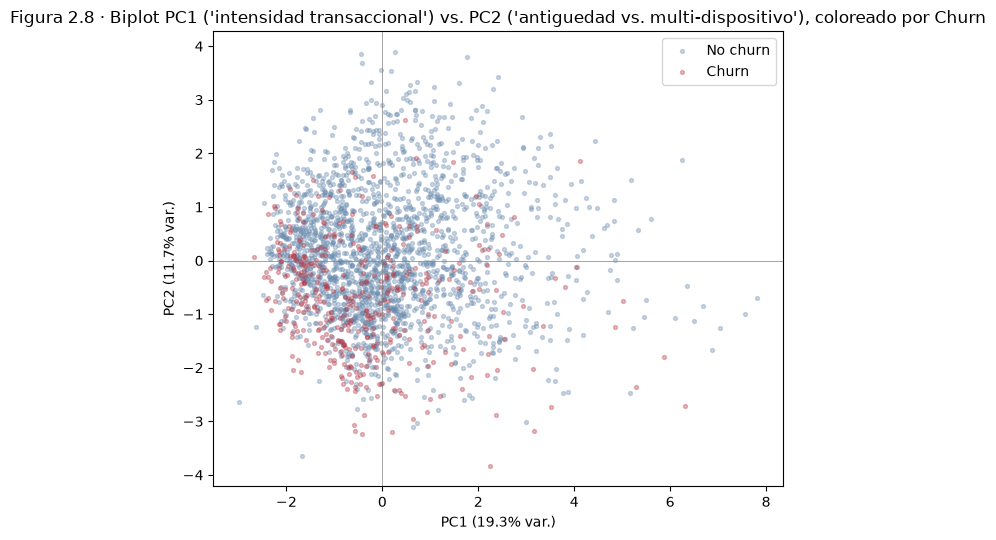

-> artifacts/pca.joblib guardado (lo usa el modulo 1 de la app)
Lectura: no se observa una separacion clara de Churn en el plano PC1-PC2; la PCA aqui es descriptiva/de reduccion, no un clasificador -- consistente con que el torneo predictivo (Fase 3) usa las 12 variables originales, no las componentes.


In [14]:
Z = pipe.transform(X_train[prep.NUMERIC_COLS])
churn_train = y_train.to_numpy()

fig, ax = plt.subplots(figsize=(6.5, 5.5))
for churn_val, color, label in [(0, "#6a8caf", "No churn"), (1, "#b23a48", "Churn")]:
    mask = churn_train == churn_val
    ax.scatter(Z[mask, 0], Z[mask, 1], s=8, alpha=0.35, color=color, label=label)
ax.axhline(0, color="grey", linewidth=0.5)
ax.axvline(0, color="grey", linewidth=0.5)
ax.set_title("Figura 2.8 · Biplot PC1 ('intensidad transaccional') vs. PC2 ('antiguedad vs. multi-dispositivo'), coloreado por Churn")
ax.set_xlabel(f"PC1 ({evr['PC1']:.1%} var.)")
ax.set_ylabel(f"PC2 ({evr['PC2']:.1%} var.)")
ax.legend()
fig.tight_layout()
plt.show()

joblib.dump(pipe, ARTIFACTS / "pca.joblib", compress=3)
print("-> artifacts/pca.joblib guardado (lo usa el modulo 1 de la app)")
print("Lectura: no se observa una separacion clara de Churn en el plano PC1-PC2; la PCA aqui es descriptiva/de reduccion, no un clasificador -- consistente con que el torneo predictivo (Fase 3) usa las 12 variables originales, no las componentes.")


## 2.6 · Síntesis para la app (módulo 1 "Diagnóstico")

- `artifacts/pca.joblib`: pipeline `Imputer(mediana) -> StandardScaler -> PCA` ajustado solo en Train sobre `src.preprocessing.NUMERIC_COLS`. La app lo usa con `.transform(X)` para ubicar a un cliente nuevo en el biplot PC1-PC2.
- **PC1 ("intensidad transaccional"):** `OrderCount`, `CouponUsed`, `CashbackAmount`, `DaySinceLastOrder`.
- **PC2 ("antigüedad vs. uso multi-dispositivo"):** `Tenure` (+) contra `HourSpendOnApp`/`NumberOfDeviceRegistered` (−).
- El MCO, Gauss-Markov, influencia y VIF de este borrador son un ejercicio de diagnóstico estadístico (Rúbrica D2); no alimentan la app ni el pipeline causal de Fase 4.
- Detalle completo (tablas, hallazgos que contradicen `docs/02` y la comparación Huber/RANSAC) en `BITACORA.md`, Entrada 2 §2.2 y filas 6-11.